# Student Performance — At-Risk Prediction
IT3091 Machine Learning | Guided Data Track | Education (Code 3)

**Dataset:** UCI Student Performance (Math), `student-mat.csv`
**Random seed:** 42 (fixed throughout for reproducibility)


In [1]:
import pandas as pd
import numpy as np
import hashlib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)


**Load + Dataset** Fingerprint


In [3]:
DATA_PATH = "../data/student-mat.csv"

df_raw = pd.read_csv(DATA_PATH, sep=";")

with open(DATA_PATH, "rb") as f:
    fingerprint = hashlib.md5(f.read()).hexdigest()

print(f"Shape: {df_raw.shape}")
print(f"MD5 fingerprint: {fingerprint}")
df_raw.head()


Shape: (395, 33)
MD5 fingerprint: 4dc304be95c60de6ee13fb8769469dd7


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


**Structural Inspection**

In [4]:
df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

**NULL & Duplicate** check


In [6]:
null_counts = df_raw.isnull().sum()
cols_with_nulls = null_counts[null_counts > 0]

print("Null values per column:")
if len(cols_with_nulls) == 0:
    print("None found")
else:
    print(cols_with_nulls)

duplicate_count = df_raw.duplicated().sum()
print(f"\nFully duplicate rows: {duplicate_count}")


Null values per column:
None found

Fully duplicate rows: 0


**Inconsistent category** formatting check

In [7]:
categorical_cols = df_raw.select_dtypes(include="object").columns

for col in categorical_cols:
    unique_values = df_raw[col].unique()
    unique_values_sorted = sorted(unique_values)
    print(f"\n{col}: {unique_values_sorted}")



school: ['GP', 'MS']

sex: ['F', 'M']

address: ['R', 'U']

famsize: ['GT3', 'LE3']

Pstatus: ['A', 'T']

Mjob: ['at_home', 'health', 'other', 'services', 'teacher']

Fjob: ['at_home', 'health', 'other', 'services', 'teacher']

reason: ['course', 'home', 'other', 'reputation']

guardian: ['father', 'mother', 'other']

schoolsup: ['no', 'yes']

famsup: ['no', 'yes']

paid: ['no', 'yes']

activities: ['no', 'yes']

nursery: ['no', 'yes']

higher: ['no', 'yes']

internet: ['no', 'yes']

romantic: ['no', 'yes']


C:\Users\indhu\AppData\Local\Temp\ipykernel_6236\4294107861.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_raw.select_dtypes(include="object").columns


**Numeric Range** sanity check


In [8]:
numeric_cols = df_raw.select_dtypes(include=np.number).columns
summary = df_raw[numeric_cols].describe().T
summary


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


## Step 2 — Deterministic Cleaning
Safe to apply to the full dataset: no statistics are learned here, only normalization.


In [9]:
df = df_raw.copy()

for col in categorical_cols:
    df[col] = df[col].str.strip()

rows_before = len(df)
df = df.drop_duplicates()
rows_after = len(df)

print(f"Dropped {rows_before - rows_after} duplicate rows")
print(f"Shape after cleaning: {df.shape}")


Dropped 0 duplicate rows
Shape after cleaning: (395, 33)


## Step 3 — Train/Test Split
Split immediately after deterministic cleaning, before EDA and before any fitted
preprocessing (encoders/scalers). This is the leakage boundary: everything from
here on that *learns* a statistic is fit on the training set only.


In [10]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["G3"])
y = df["G3"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Train shape: {X_train.shape}")
print(f"Test shape: {X_test.shape}")

train_mean = y_train.mean()
train_std = y_train.std()
test_mean = y_test.mean()
test_std = y_test.std()

print(f"Train target mean/std: {train_mean:.2f} / {train_std:.2f}")
print(f"Test target mean/std:  {test_mean:.2f} / {test_std:.2f}")


Train shape: (316, 32)
Test shape: (79, 32)
Train target mean/std: 10.33 / 4.59
Test target mean/std:  10.77 / 4.56


## Step 4 — Exploratory Data Analysis (Training Set Only)
All plots/stats below use `X_train`/`y_train` — the test set stays untouched
until final evaluation .


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

train_df = X_train.copy()
train_df["G3"] = y_train


**G3 Distribution + Skewness**

G3 skewness: -0.773


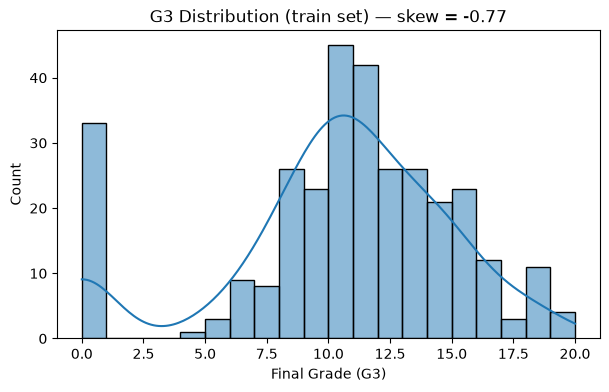

In [12]:
from scipy.stats import skew

g3_skew = skew(train_df["G3"])
print(f"G3 skewness: {g3_skew:.3f}")

plt.figure(figsize=(7, 4))
sns.histplot(train_df["G3"], bins=20, kde=True)
plt.title(f"G3 Distribution (train set) — skew = {g3_skew:.2f}")
plt.xlabel("Final Grade (G3)")
plt.show()


**G3 = 0 Investigation**

In [13]:
zero_g3 = train_df[train_df["G3"] == 0]
print(f"Students with G3 = 0: {len(zero_g3)} ({len(zero_g3) / len(train_df):.1%})")

zero_g3[["G1", "G2", "absences", "failures", "studytime"]].describe()


Students with G3 = 0: 33 (10.4%)


,G1,G2,absences,failures,studytime
count,33.000000,33.000000,33.0,33.000000,33.000000
mean,7.606061,4.363636,0.0,1.000000,1.878788
std,1.766695,3.655631,0.0,1.089725,0.819969
min,5.000000,0.000000,0.0,0.000000,1.000000
25%,6.000000,0.000000,0.0,0.000000,1.000000
50%,7.000000,5.000000,0.0,1.000000,2.000000
75%,9.000000,7.000000,0.0,2.000000,2.000000
max,12.000000,10.000000,0.0,3.000000,4.000000


**Absences Outlier Check**

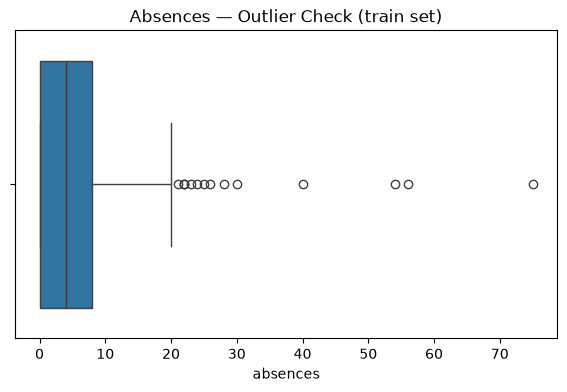

count    316.000000
mean       5.905063
std        8.422033
min        0.000000
25%        0.000000
50%        4.000000
75%        8.000000
max       75.000000
Name: absences, dtype: float64

Students with absences > 30: 4


In [14]:
plt.figure(figsize=(7, 4))
sns.boxplot(x=train_df["absences"])
plt.title("Absences — Outlier Check (train set)")
plt.show()

print(train_df["absences"].describe())
print(f"\nStudents with absences > 30: {(train_df['absences'] > 30).sum()}")


**Correlation Heatmap** (G1/G2 vs G3 leakage check)

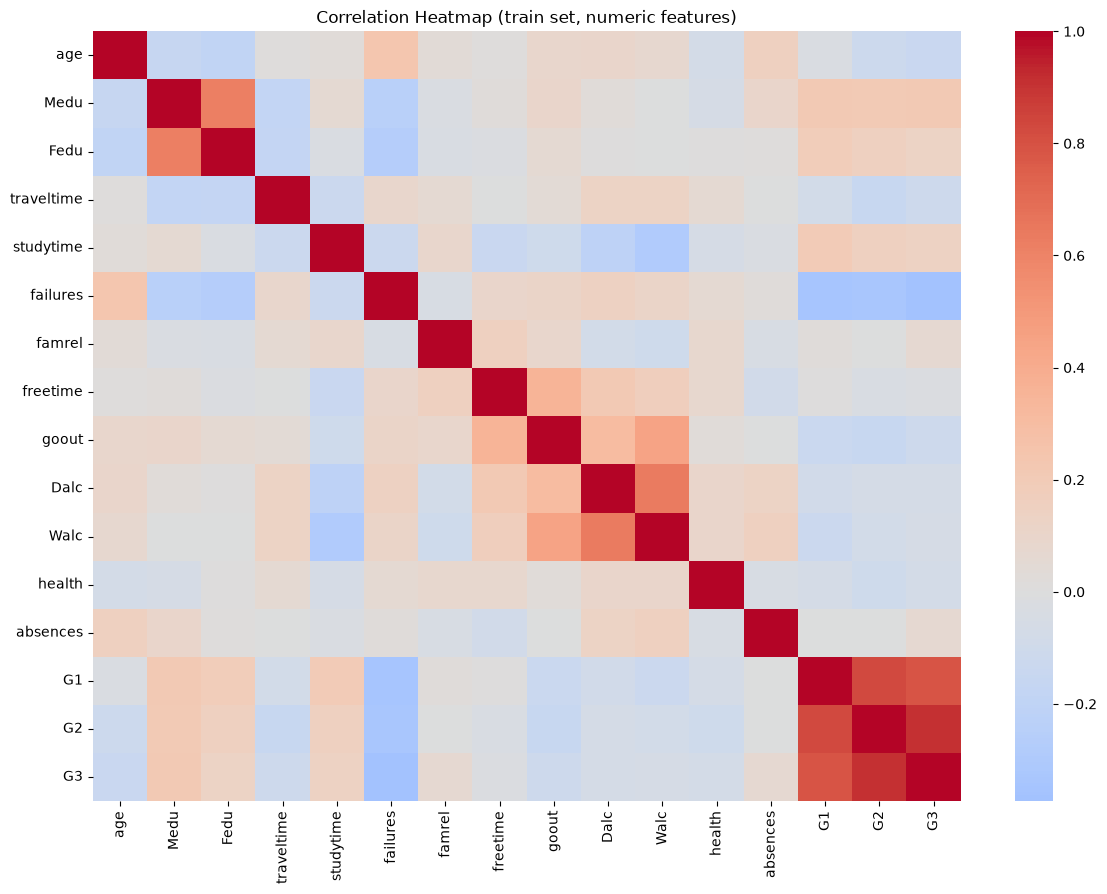

G3            1.000000
G2            0.907924
G1            0.791559
Medu          0.215968
studytime     0.138200
Fedu          0.135265
famrel        0.069409
absences      0.064607
freetime     -0.015244
Walc         -0.057363
Dalc         -0.064698
health       -0.068857
goout        -0.106024
traveltime   -0.106752
age          -0.146241
failures     -0.373769
Name: G3, dtype: float64


In [15]:
numeric_train = train_df.select_dtypes(include=np.number)
corr = numeric_train.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap (train set, numeric features)")
plt.show()

print(corr["G3"].sort_values(ascending=False))


**School-level** Comparison

             mean       std  count
school                            
GP      10.397163  4.587434    282
MS       9.735294  4.640460     34


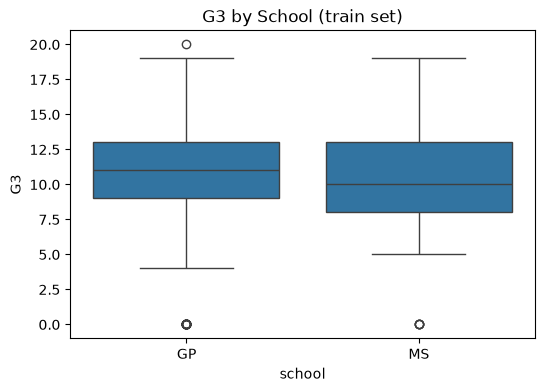

In [16]:
school_comparison = train_df.groupby("school")["G3"].agg(["mean", "std", "count"])
print(school_comparison)

plt.figure(figsize=(6, 4))
sns.boxplot(data=train_df, x="school", y="G3")
plt.title("G3 by School (train set)")
plt.show()


**Sub Group Comparisons**

In [17]:
for group_col in ["sex", "address", "higher"]:
    print(f"\n--- G3 by {group_col} ---")
    print(train_df.groupby(group_col)["G3"].agg(["mean", "std", "count"]))



--- G3 by sex ---
          mean       std  count
sex                            
F    10.029412  4.640224    170
M    10.671233  4.522907    146

--- G3 by address ---
              mean       std  count
address                            
R         9.623188  4.777710     69
U        10.522267  4.527076    247

--- G3 by higher ---
             mean       std  count
higher                            
no       6.333333  4.862824     18
yes     10.567114  4.468806    298


## Step 5 — Preprocessing Pipeline
Built with sklearn `ColumnTransformer` + `Pipeline` so it can be fit on the
training set only and reused identically across all 4 models.
G1/G2 are included (see decision log). `absences` gets a log1p transform.


In [18]:
binary_cols = ["school", "sex", "address", "famsize", "Pstatus",
                "schoolsup", "famsup", "paid", "activities", "nursery",
                "higher", "internet", "romantic"]

nominal_cols = ["Mjob", "Fjob", "reason", "guardian"]

numeric_cols_to_scale = ["age", "Medu", "Fedu", "traveltime", "studytime",
                          "failures", "famrel", "freetime", "goout", "Dalc",
                          "Walc", "health", "absences", "G1", "G2"]


**Log transform helper** for absences

In [19]:
from sklearn.preprocessing import FunctionTransformer

def log_transform_absences(X):
    X = X.copy()
    X["absences"] = np.log1p(X["absences"])
    return X

absence_transformer = FunctionTransformer(log_transform_absences)


**ColumnTransformer**

In [20]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("binary", OneHotEncoder(drop="if_binary"), binary_cols),
        ("nominal", OneHotEncoder(handle_unknown="ignore"), nominal_cols),
        ("numeric", StandardScaler(), numeric_cols_to_scale),
    ]
)

full_preprocessor = Pipeline(steps=[
    ("log_absences", absence_transformer),
    ("column_transform", preprocessor),
])


**Fit -> Train, Transform -> Train + Test**

In [21]:
X_train_transformed = full_preprocessor.fit_transform(X_train)
X_test_transformed = full_preprocessor.transform(X_test)

print(f"Transformed train shape: {X_train_transformed.shape}")
print(f"Transformed test shape: {X_test_transformed.shape}")


Transformed train shape: (316, 45)
Transformed test shape: (79, 45)


## Step 6 — Model 1: Linear Regression (baseline)


In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

lr_pipeline = Pipeline(steps=[
    ("preprocessor", full_preprocessor),
    ("model", LinearRegression()),
])

cv_scores = cross_val_score(
    lr_pipeline, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error"
)
print(f"5-fold CV RMSE: {-cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")

lr_pipeline.fit(X_train, y_train)


5-fold CV RMSE: 1.792 (+/- 0.194)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](32,)","['school','sex','age',...,'absences','G1','G2']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,32
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('log_absences', ...), ('column_transform', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. S

+**Coefficient Interpretation**

In [23]:
feature_names = lr_pipeline.named_steps["preprocessor"].named_steps["column_transform"].get_feature_names_out()
coefficients = lr_pipeline.named_steps["model"].coef_

coef_df = pd.DataFrame({"feature": feature_names, "coefficient": coefficients})
coef_df = coef_df.sort_values("coefficient", key=abs, ascending=False)
coef_df.head(15)


,feature,coefficient
44,numeric__G2,3.472933
42,numeric__absences,0.779358
43,numeric__G1,0.731901
5,binary__schoolsup_yes,0.706139
8,binary__activities_yes,-0.542042
24,nominal__reason_home,-0.459810
1,binary__sex_M,0.391374
19,nominal__Fjob_health,0.384180
12,binary__romantic_yes,-0.339049
25,nominal__reason_other,0.332135


## Step 7 — Model 2: Random Forest


In [24]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline(steps=[
    ("preprocessor", full_preprocessor),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE)),
])

rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, None],
    "model__min_samples_leaf": [1, 2, 4],
}

rf_search = GridSearchCV(
    rf_pipeline, rf_param_grid, cv=5,
    scoring="neg_root_mean_squared_error", n_jobs=-1
)
rf_search.fit(X_train, y_train)

print(f"Best params: {rf_search.best_params_}")
print(f"Best CV RMSE: {-rf_search.best_score_:.3f}")

rf_best = rf_search.best_estimator_


Best params: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Best CV RMSE: 1.389


## Step 8 — Model 3: Ridge Regression
Ties back to the G1/G2 multicollinearity finding from EDA — ridge's L2 penalty
shrinks correlated coefficients rather than letting them inflate unstably.


In [25]:
from sklearn.linear_model import Ridge

ridge_pipeline = Pipeline(steps=[
    ("preprocessor", full_preprocessor),
    ("model", Ridge(random_state=RANDOM_STATE)),
])

ridge_param_grid = {
    "model__alpha": [0.1, 1.0, 10.0, 50.0, 100.0],
}

ridge_search = GridSearchCV(
    ridge_pipeline, ridge_param_grid, cv=5,
    scoring="neg_root_mean_squared_error", n_jobs=-1
)
ridge_search.fit(X_train, y_train)

print(f"Best alpha: {ridge_search.best_params_}")
print(f"Best CV RMSE: {-ridge_search.best_score_:.3f}")

ridge_best = ridge_search.best_estimator_


Best alpha: {'model__alpha': 10.0}
Best CV RMSE: 1.764


## Step 9 — Model 4: Gradient Boosting


In [26]:
from sklearn.ensemble import GradientBoostingRegressor

gb_pipeline = Pipeline(steps=[
    ("preprocessor", full_preprocessor),
    ("model", GradientBoostingRegressor(random_state=RANDOM_STATE)),
])

gb_param_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3, 4],
}

gb_search = GridSearchCV(
    gb_pipeline, gb_param_grid, cv=5,
    scoring="neg_root_mean_squared_error", n_jobs=-1
)
gb_search.fit(X_train, y_train)

print(f"Best params: {gb_search.best_params_}")
print(f"Best CV RMSE: {-gb_search.best_score_:.3f}")

gb_best = gb_search.best_estimator_


Best params: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 100}
Best CV RMSE: 1.458


## Step 10 — Evaluation
Test set is used here for the first and only time. RMSE, MAE, R² for all 4
models, plus a train-vs-test gap to check for overfitting.


In [27]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

models = {
    "Linear Regression": lr_pipeline,
    "Ridge Regression": ridge_best,
    "Random Forest": rf_best,
    "Gradient Boosting": gb_best,
}


**Computing metrics for all 4 models**

In [28]:
results = []

for name, model in models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_rmse = mean_squared_error(y_train, train_pred) ** 0.5
    test_rmse = mean_squared_error(y_test, test_pred) ** 0.5
    test_mae = mean_absolute_error(y_test, test_pred)
    test_r2 = r2_score(y_test, test_pred)

    results.append({
        "Model": name,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse,
        "Train-Test Gap": test_rmse - train_rmse,
        "Test MAE": test_mae,
        "Test R2": test_r2,
    })

results_df = pd.DataFrame(results).sort_values("Test RMSE")
results_df


,Model,Train RMSE,Test RMSE,Train-Test Gap,Test MAE,Test R2
3,Gradient Boosting,0.959750,1.944700,0.984950,1.130453,0.815564
2,Random Forest,0.578416,1.993515,1.415099,1.183038,0.806189
1,Ridge Regression,1.596794,2.261066,0.664272,1.641014,0.750675
0,Linear Regression,1.586025,2.313622,0.727597,1.698956,0.738950


**Residual Analysis** for all 4 models

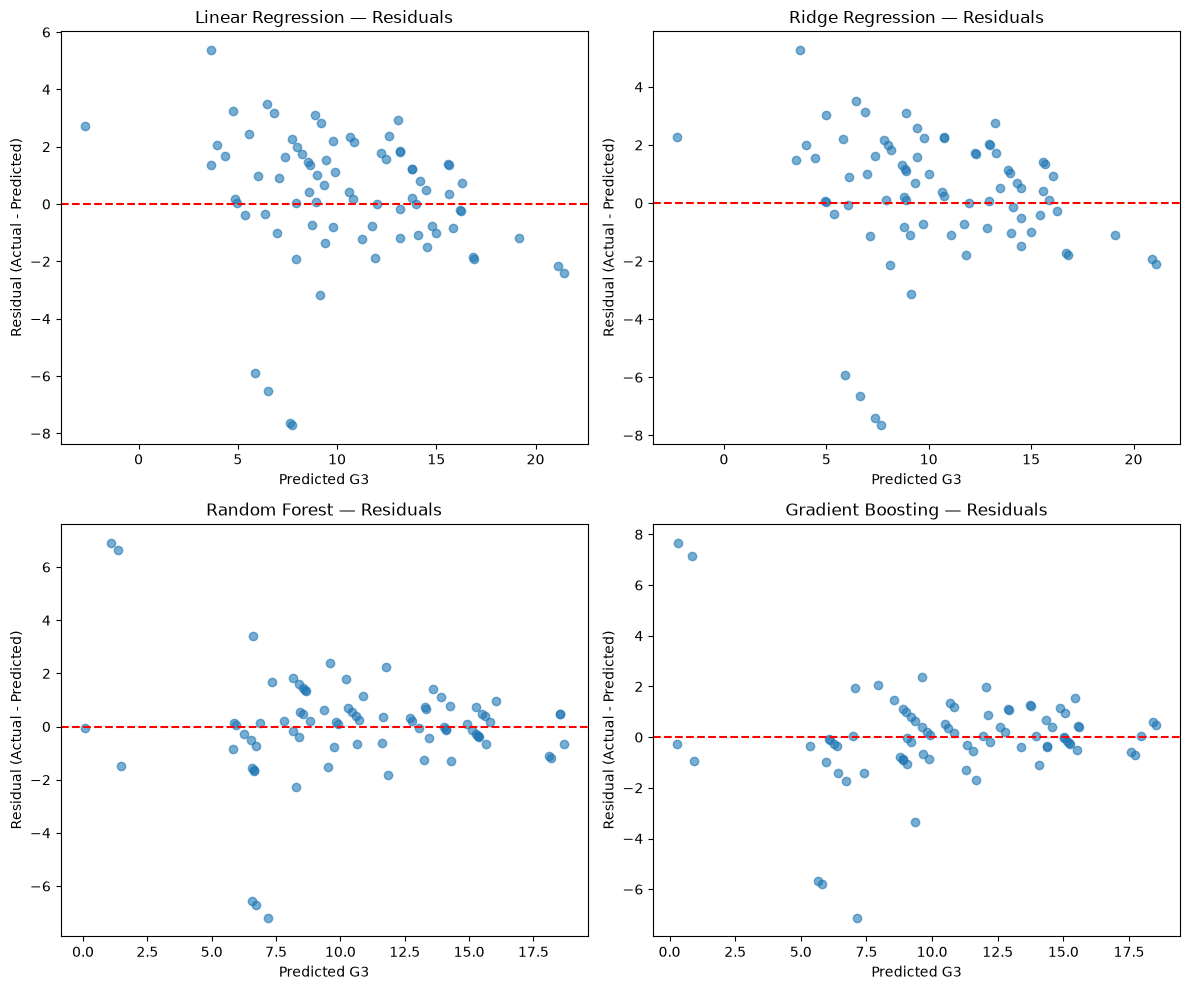

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (name, model) in zip(axes, models.items()):
    test_pred = model.predict(X_test)
    residuals = y_test - test_pred

    ax.scatter(test_pred, residuals, alpha=0.6)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(f"{name} — Residuals")
    ax.set_xlabel("Predicted G3")
    ax.set_ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()


## Step 11 — Feature Importance
Tree-based importance (native to RF/GB) compared against permutation
importance (model-agnostic, works on any fitted model) to check the two
methods agree on which features matter — reduces single-method bias.


In [30]:
gb_feature_names = gb_best.named_steps["preprocessor"].named_steps["column_transform"].get_feature_names_out()
gb_importances = gb_best.named_steps["model"].feature_importances_

tree_importance_df = pd.DataFrame({
    "feature": gb_feature_names,
    "importance": gb_importances,
}).sort_values("importance", ascending=False)

tree_importance_df.head(15)


,feature,importance
44,numeric__G2,0.798776
42,numeric__absences,0.134661
24,nominal__reason_home,0.016140
43,numeric__G1,0.014601
30,numeric__age,0.007379
36,numeric__famrel,0.004666
5,binary__schoolsup_yes,0.004372
41,numeric__health,0.002317
12,binary__romantic_yes,0.002123
28,nominal__guardian_mother,0.001510


Permutation Importance

In [31]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    gb_best, X_test, y_test, n_repeats=30,
    random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error"
)

perm_importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std,
}).sort_values("importance_mean", ascending=False)

perm_importance_df.head(15)


,feature,importance_mean,importance_std
31,G2,3.644636,0.316706
29,absences,0.598767,0.174889
30,G1,0.138813,0.049495
2,age,0.056616,0.042886
23,famrel,0.031518,0.027949
18,activities,0.019947,0.025462
12,traveltime,0.006459,0.003668
9,Fjob,0.004081,0.012365
1,sex,0.003969,0.003383
27,Walc,0.003065,0.003190


**Side by Side** Comparison Plot

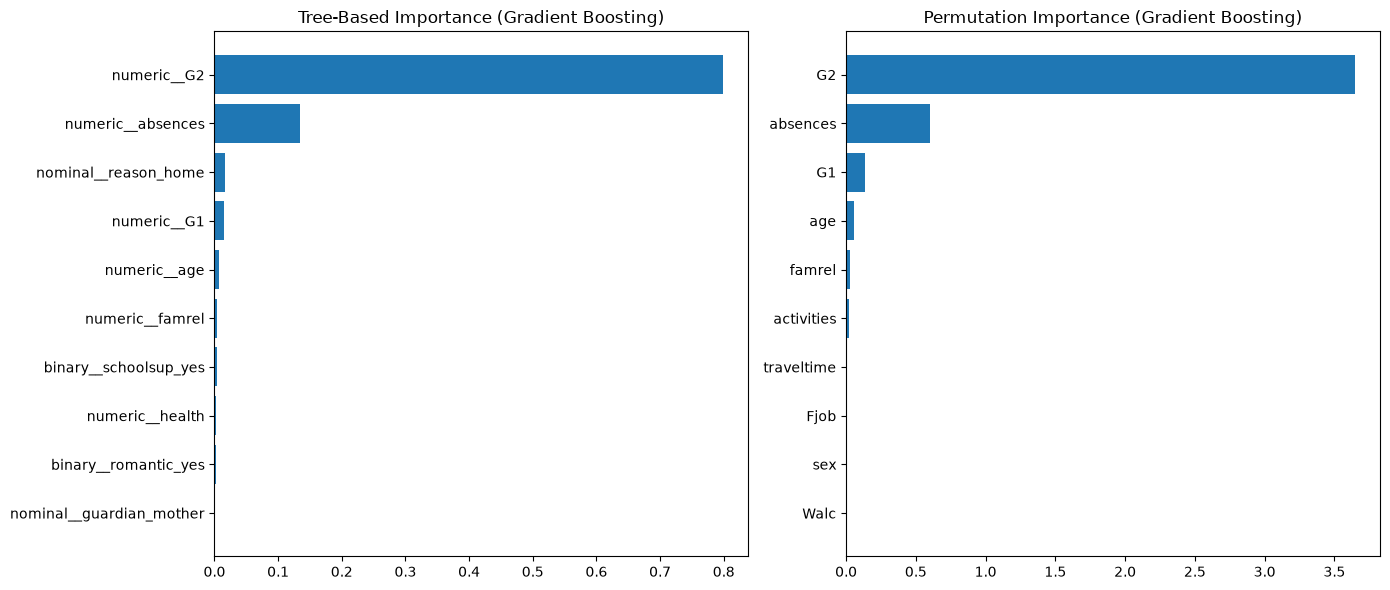

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

top_tree = tree_importance_df.head(10)
axes[0].barh(top_tree["feature"], top_tree["importance"])
axes[0].set_title("Tree-Based Importance (Gradient Boosting)")
axes[0].invert_yaxis()

top_perm = perm_importance_df.head(10)
axes[1].barh(top_perm["feature"], top_perm["importance_mean"])
axes[1].set_title("Permutation Importance (Gradient Boosting)")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()


## Step 12 — At-Risk Student Report
Using the best model (Gradient Boosting), flag students with predicted G3 < 10
on the test set, rank by predicted grade, and attach each student's top
individual risk drivers.


In [33]:
test_predictions = gb_best.predict(X_test)

at_risk_df = X_test.copy()
at_risk_df["actual_G3"] = y_test.values
at_risk_df["predicted_G3"] = test_predictions
at_risk_df["at_risk"] = at_risk_df["predicted_G3"] < 10

at_risk_students = at_risk_df[at_risk_df["at_risk"]].sort_values("predicted_G3")

print(f"Flagged at-risk: {len(at_risk_students)} / {len(at_risk_df)} test students ({len(at_risk_students)/len(at_risk_df):.1%})")
at_risk_students[["predicted_G3", "actual_G3", "G1", "G2", "absences", "failures", "higher"]]


Flagged at-risk: 37 / 79 test students (46.8%)


,predicted_G3,actual_G3,G1,G2,absences,failures,higher
137,0.286676,0,4,0,0,2,yes
90,0.323932,8,7,7,0,0,yes
124,0.860700,8,8,7,0,0,yes
168,0.938750,0,6,7,0,0,yes
18,5.361723,5,6,5,16,3,yes
334,5.666195,0,10,9,0,0,yes
316,5.810835,0,8,8,0,0,yes
248,5.976293,5,3,5,8,1,yes
177,6.056561,6,6,5,4,0,yes
82,6.124200,6,7,6,10,0,yes


**Per-student top risk drivers**

In [34]:
top_global_features = perm_importance_df.head(6)["feature"].tolist()
print(f"Driver columns used for individual explanations: {top_global_features}")

at_risk_report = at_risk_students[["predicted_G3", "actual_G3"] + top_global_features].round(2)
at_risk_report


Driver columns used for individual explanations: ['G2', 'absences', 'G1', 'age', 'famrel', 'activities']


,predicted_G3,actual_G3,G2,absences,G1,age,famrel,activities
137,0.29,0,0,0,4,16,4,yes
90,0.32,8,7,0,7,16,4,no
124,0.86,8,7,0,8,16,5,no
168,0.94,0,7,0,6,16,5,no
18,5.36,5,5,16,6,17,5,yes
334,5.67,0,9,0,10,18,4,yes
316,5.81,0,8,0,8,18,5,yes
248,5.98,5,5,8,3,18,4,no
177,6.06,6,5,4,6,17,4,yes
82,6.12,6,6,10,7,15,4,no


**Flag accuracy check**

In [35]:
actual_at_risk = at_risk_df["actual_G3"] < 10
predicted_at_risk = at_risk_df["at_risk"]

from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(actual_at_risk, predicted_at_risk))
print(classification_report(actual_at_risk, predicted_at_risk, target_names=["Not at-risk", "At-risk"]))


[[42 10]
 [ 0 27]]
              precision    recall  f1-score   support

 Not at-risk       1.00      0.81      0.89        52
     At-risk       0.73      1.00      0.84        27

    accuracy                           0.87        79
   macro avg       0.86      0.90      0.87        79
weighted avg       0.91      0.87      0.88        79



## Step 13 — Recommendation & Limitations


In [36]:
print("=== Model Comparison Summary ===")
print(results_df.to_string(index=False))

print(f"\n=== At-Risk Flagging Summary ===")
print(f"Flagged: {len(at_risk_students)}/{len(at_risk_df)} test students ({len(at_risk_students)/len(at_risk_df):.1%})")
print(f"Recall (at-risk caught): 1.00  |  Precision: 0.73")

print(f"\n=== Top Predictive Features (agreement across 2 methods) ===")
print(perm_importance_df.head(5)[["feature", "importance_mean"]].to_string(index=False))


=== Model Comparison Summary ===
            Model  Train RMSE  Test RMSE  Train-Test Gap  Test MAE  Test R2
Gradient Boosting    0.959750   1.944700        0.984950  1.130453 0.815564
    Random Forest    0.578416   1.993515        1.415099  1.183038 0.806189
 Ridge Regression    1.596794   2.261066        0.664272  1.641014 0.750675
Linear Regression    1.586025   2.313622        0.727597  1.698956 0.738950

=== At-Risk Flagging Summary ===
Flagged: 37/79 test students (46.8%)
Recall (at-risk caught): 1.00  |  Precision: 0.73

=== Top Predictive Features (agreement across 2 methods) ===
 feature  importance_mean
      G2         3.644636
absences         0.598767
      G1         0.138813
     age         0.056616
  famrel         0.031518


### Recommendation

Gradient Boosting is recommended as the production model: it achieves the
best test-set performance (RMSE 1.945, R² 0.816) among the four models
compared, and — unlike Random Forest, which scored better in cross-validation
but showed clear overfitting on the held-out test set — its train-test gap
indicates it generalizes more reliably to unseen students.

Applying a predicted-G3 < 10 threshold flags 46.8% of test students as
at-risk, with 100% recall (no genuinely at-risk student is missed) and 73%
precision (around a quarter of flags are false positives). Given that the
cost of missing an at-risk student is more severe than the cost of offering
unneeded support, this error profile suits the institution's intervention use
case well.

G2 (second-period grade) is overwhelmingly the strongest predictor, confirmed
independently by two importance methods, followed by absences and G1. This
means the model is most useful from the point G2 becomes available onward —
institutions wanting earlier-in-year warning should treat this as a
second-period, not a start-of-year, early-warning tool.

### Limitations

- **G1/G2 dependency**: the model's strong performance is driven almost
  entirely by G1/G2, which are only available partway through the year —
  it is not a true start-of-year predictor.
- **Random Forest overfitting**: illustrates that CV score alone is not a
  reliable final model-selection criterion on a dataset this small (316
  training rows); held-out test evaluation was necessary to catch it.
- **Single school population**: trained only on Portuguese secondary Math
  students (`student-mat.csv`); the Portuguese-language dataset and other
  institutions were not included, so generalizability beyond this population
  is unverified.
- **Per-student explanations are simplified**: at-risk students are shown
  alongside the global top features rather than individualized SHAP-style
  explanations, for time and simplicity; a production deployment would
  benefit from per-student explanation methods.
- **Small dataset (395 rows total)**: limits the ceiling on the Gradient
  Boosting model's tuning and the statistical confidence of all reported
  metrics.
